<a href="https://colab.research.google.com/github/ikabrain/UCS772-CV-NLP-Lab/blob/main/NLP_CV_assign8/CV_assign8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 8 - Face Recognition
---

Face recognition is often described as a process that first involves four steps; they are face detection, face alignment, feature extraction, and finally face recognition. Develop a face recognition system considering above stages for your dataset and measure the performance for advanced models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cv2
from google.colab.patches import cv2_imshow

In [2]:
SEED = 42
rng = np.random.default_rng(SEED)

## Getting the Data Ready
---
I'll be using the LFW (Labelled Faces in the Wild) dataset, keeping only people that have enough photos, but not too many (to prevent one person from dominating the metrics).

In [3]:
MIN_FACES  = 20 # Keeps only people with at least this many photos
MAX_PER_ID = 40 # Cap photos per person so one person cannot dominate the metrics

In [4]:
def load_lfw(min_faces_per_person):
    """Loads the LFW dataset and pre-processes images.

    Args:
        min_faces_per_person (int): Minimum number of faces per person to include.

    Returns:
        tuple: (images, labels, target_names).
    """
    from sklearn.datasets import fetch_lfw_people

    lfw = fetch_lfw_people(
        min_faces_per_person=min_faces_per_person,
        color=True,
        resize=1.0,
        slice_=None, # slice_=None keeps the whole 250x250 photo (the default crops to a small central patch) as our detector needs the surrounding context
        funneled=True
    )
    arr = lfw.images

    scale = 255.0 if arr.max() <= 1.0 + 1e-6 else 1.0       # sklearn returns floats; bring back to 0..255
    imgs = [np.ascontiguousarray(np.clip(a * scale, 0, 255).astype(np.uint8)[..., ::-1]) for a in arr]  # RGB -> BGR

    return imgs, lfw.target.copy(), np.array(lfw.target_names)


images, labels, names = load_lfw(MIN_FACES)

In [5]:
def cap_per_person(imgs, labels, max_per_person):
    """Caps the number of images per identity.

    Args:
        imgs (list): List of images.
        labels (np.ndarray): Array of identity labels.
        max_per_person (int): Maximum images allowed per person.

    Returns:
        tuple: List of capped images and array of matching labels.
    """
    keep = []
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        keep.extend(rng.permutation(idx)[:max_per_person])

    keep = np.sort(np.array(keep))

    return [imgs[i] for i in keep], labels[keep]


images, labels = cap_per_person(images, labels, MAX_PER_ID)

In [6]:
counts = np.bincount(labels, minlength=len(names))[np.unique(labels)]

print(f"We have {len(images)} images of {len(np.unique(labels))} people")
print(f"Photos per person: min {counts.min()}, median {int(np.median(counts))}, max {counts.max()}")

We have 1916 images of 62 people
Photos per person: min 20, median 31, max 40


Image shape: (250, 250, 3)


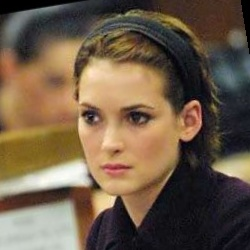

In [16]:
# Review first photo
sample = images[0]
print(f"Image shape: {sample.shape}")
cv2_imshow(sample)

## Q1: Face Detection
---
Locate one or more faces in the image and mark with a bounding box.

For this, we'll use the **YuNet Face Detector** to draw bounding boxes around face and its landmark features

In [10]:
!wget -qnc -O face_detection_yunet.onnx https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2026may.onnx
# !WARN: Use media.githubusercontent.com - the raw.githubusercontent.com URL returns a ~131-byte Git LFS pointer instead of the actual 233KB model weights

try:
    detector = cv2.FaceDetectorYN.create(
        model="face_detection_yunet.onnx",
        config="",
        input_size=(320, 320),
        score_threshold=0.6,
        nms_threshold=0.3,
        top_k=5000
    )
except:
    raise FileNotFoundError("Could not load the YuNet ONNX weights.")

In [20]:
def detect_face(img):
    h, w = img.shape[:2]
    detector.setInputSize((w, h)) # !WARN: Must match the image size!
    _, faces = detector.detect(img) # None when nothing is found
    return [] if faces is None else faces[np.argmax(faces[:, 2] * faces[:, 3])] # Prioritizes single face occupying the maximum area

sample_faces = detect_face(sample)
print(f"Bounding box: x={sample_faces[0]}, y={sample_faces[1]}, w={sample_faces[2]}, h={sample_faces[3]}")
print(f"Face area: {sample_faces[2] * sample_faces[3]}")
print(f"\nRight eye: x={sample_faces[4]}, y={sample_faces[5]}")
print(f"Left  eye: x={sample_faces[6]}, y={sample_faces[7]}")
print(f"\nNose tip: x={sample_faces[8]}, y={sample_faces[9]}")
print(f"\nMouth right corner: x={sample_faces[10]}, y={sample_faces[11]}")
print(f"Mouth  left corner: x={sample_faces[12]}, y={sample_faces[13]}")
print(f"\nConfidence: {sample_faces[14]}")

Bounding box: x=80.34251403808594, y=60.66685485839844, w=89.24433135986328, h=133.73150634765625
Face area: 11934.779296875

Right eye: x=95.23579406738281, y=114.3701171875
Left  eye: x=140.53463745117188, y=115.7506103515625

Nose tip: x=111.51416778564453, y=144.2413330078125

Mouth right corner: x=96.78152465820312, y=160.2264404296875
Mouth  left corner: x=136.07273864746094, y=161.68682861328125

Confidence: 0.944293200969696


## Q2: Face Alignment
---
Normalize the face to be consistent with the database, such as geometry and
photometrics.

## Q3: Feature Extraction
---
Extract features from the face that can be used for the recognition task.

## Q4: Face Recognition
---
Perform matching of the face against one or more known faces in a prepared
database.

## Pipeline
---